## 2. ¿Cuántos términos necesita una calculadora?

In [1]:
import numpy as np

def taylor_sin(x, n):
    if not isinstance(n, (int, np.integer)) or n < 1 or n % 2 == 0:
        raise ValueError("n debe ser un entero positivo impar")

    x = np.asarray(x, dtype=float)

    termino = x.copy()
    suma = termino.copy()

    for k in range((n - 1) // 2):
        termino = termino * (-x**2) / ((2*k + 2)*(2*k + 3))
        suma = suma + termino

    return float(suma) if suma.ndim == 0 else suma

### Escriba $P_9 (\pi) = ...$

In [2]:
print(taylor_sin(np.pi, 9))

0.006925270707505052


### Gráfica 1

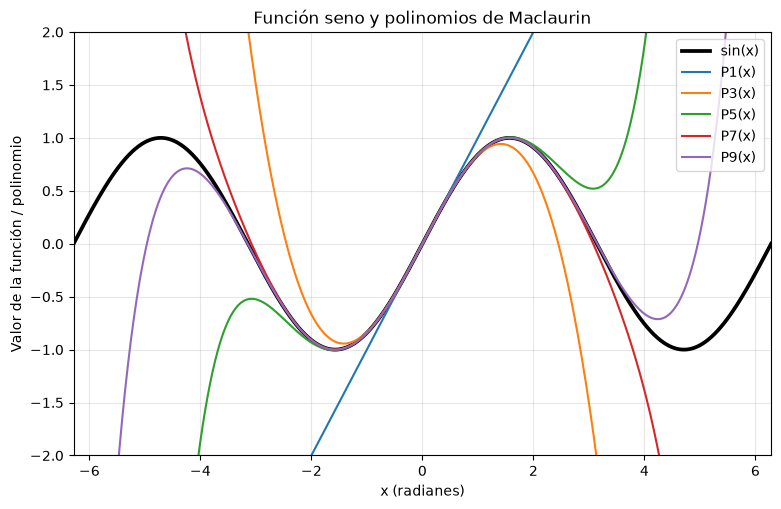

In [5]:
import matplotlib.pyplot as plt

x = np.linspace(-2*np.pi, 2*np.pi, 2001)

plt.figure(figsize=(9, 5.5))

plt.plot(x, np.sin(x), color="black",
         linewidth=2.7, label="sin(x)")

for n in [1, 3, 5, 7, 9]:
    plt.plot(x, taylor_sin(x, n),
             label=f"P{n}(x)")

plt.xlim(-2*np.pi, 2*np.pi)
plt.ylim(-2, 2)

plt.xlabel("x (radianes)")
plt.ylabel("Valor de la función / polinomio")
plt.title("Función seno y polinomios de Maclaurin")

plt.legend()
plt.grid(alpha=0.3)
plt.savefig("grafica1.png", dpi=300)
plt.show()

### Gráfica 2

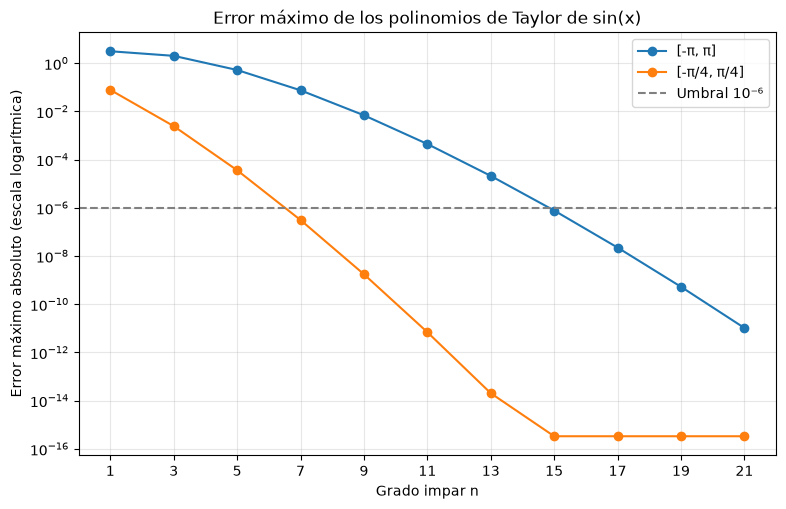

In [6]:
grados = list(range(1, 22, 2))

intervalos = [
    (-np.pi, np.pi),
    (-np.pi/4, np.pi/4)
]

errores = []

for a, b in intervalos:
    x = np.linspace(a, b, 2001)
    errores_intervalo = []

    for n in grados:
        error = np.max(
            np.abs(np.sin(x) - taylor_sin(x, n))
        )
        errores_intervalo.append(error)

    errores.append(errores_intervalo)

plt.figure(figsize=(9, 5.5))

plt.semilogy(grados, errores[0],
             marker="o", label="[-π, π]")

plt.semilogy(grados, errores[1],
             marker="o", label="[-π/4, π/4]")

plt.axhline(1e-6, color="gray",
            linestyle="--", label="Umbral 10⁻⁶")

plt.xticks(grados)
plt.xlabel("Grado impar n")
plt.ylabel("Error máximo absoluto (escala logarítmica)")
plt.title("Error máximo de los polinomios de Taylor de sin(x)")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.savefig("grafica2.png", dpi=300)
plt.show()

## 3. Una función suave cuya serie no converge

In [14]:
def serie_geometrica(x, N):
    if not isinstance(N, (int, np.integer)) or N < 0:
        raise ValueError("N debe ser un entero no negativo")

    x = np.asarray(x, dtype=float)

    termino = np.ones_like(x, dtype=float)
    suma = termino.copy()

    for k in range(1, N + 1):
        termino = termino * (-x**2)
        suma = suma + termino

    return float(suma) if suma.ndim == 0 else suma

print(serie_geometrica(0.9,40))
print(serie_geometrica(1.1,40))

0.5525839582018942
1121.9747781214605


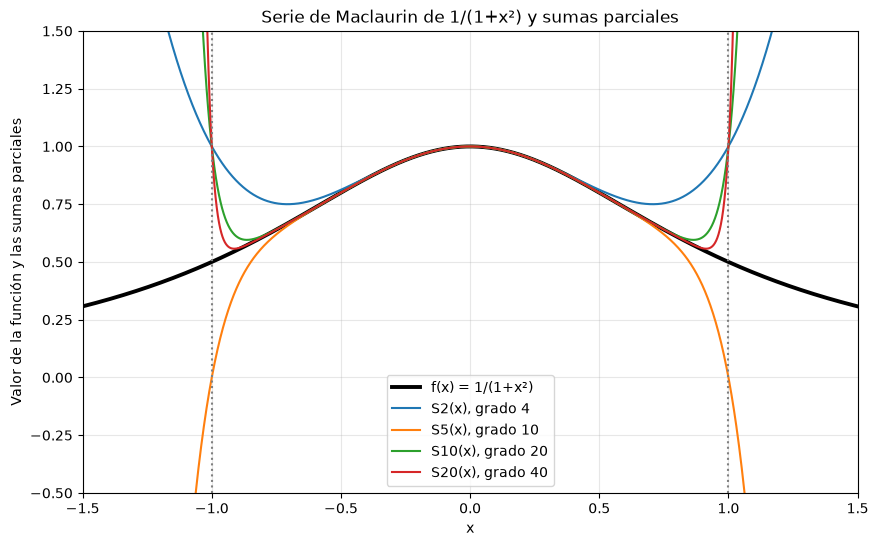

In [8]:
x = np.linspace(-1.5, 1.5, 2001)

plt.figure(figsize=(10, 6))

plt.plot(x, 1 / (1 + x**2),
         color="black", linewidth=2.8,
         label="f(x) = 1/(1+x²)")

for N in [2, 5, 10, 20]:
    plt.plot(x, serie_geometrica(x, N),
             label=f"S{N}(x), grado {2*N}")

plt.axvline(-1, color="gray", linestyle=":")
plt.axvline(1, color="gray", linestyle=":")

plt.xlim(-1.5, 1.5)
plt.ylim(-0.5, 1.5)

plt.xlabel("x")
plt.ylabel("Valor de la función y las sumas parciales")
plt.title("Serie de Maclaurin de 1/(1+x²) y sumas parciales")

plt.legend()
plt.grid(alpha=0.3)
plt.savefig("grafica3.png", dpi=300)
plt.show()


## 4. La serie correcta con la aritmética de la computadora

In [15]:
import math

def taylor_exp(x, n):
    termino = 1.0
    suma = termino

    for k in range(1, n + 1):
        termino = termino * x / k
        suma += termino

    return suma

aproximacion = taylor_exp(-20, 100)
valor_real = math.exp(-20)

print("P100(-20):", aproximacion)
print("math.exp(-20):", valor_real)
print("Error absoluto:", abs(aproximacion - valor_real))

P100(-20): 5.621884472130418e-09
math.exp(-20): 2.061153622438558e-09
Error absoluto: 3.5607308496918597e-09


In [16]:
termino = 1.0
mayor = abs(termino)
indice = 0

for k in range(1, 101):
    termino = termino * (-20) / k

    if abs(termino) > mayor:
        mayor = abs(termino)
        indice = k

print("Mayor valor absoluto:", mayor)
print("Índice encontrado:", indice)

Mayor valor absoluto: 43099804.121821776
Índice encontrado: 19
